# Exploratory Data Analysis (EDA)
## Airfoil Self-Noise Prediction

**Project:** Machine Learning-Based Prediction of Airfoil Self-Noise

**Objective:** To explore the NASA Airfoil Self-Noise dataset, understand the distribution of its features, identify correlations, detect missing values and visualise relationships between aerodynamic parameters and sound pressure level.

**Dataset:** NASA Airfoil Self-Noise Dataset (UCI Machine Learning Repository).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Set the visualisation style
sns.set_theme(style="whitegrid")

# Locate the project directory
ROOT = Path.cwd()

if not (ROOT / "dataset" / "airfoil_self_noise.dat").exists():
    ROOT = ROOT.parent

# Define dataset and output paths
DATA_PATH = ROOT / "dataset" / "airfoil_self_noise.dat"
PLOT_DIR = ROOT / "results" / "plots"

# Create plots folder if it doesn't exist
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully!")
print("Project directory:", ROOT)

Libraries imported successfully!
Project directory: /Users/goldeemishra/Documents/Airfoil-self-noise-prediction


In [3]:
# Column names of the NASA Airfoil Self-Noise dataset

columns = [
    "Frequency",
    "Angle of Attack",
    "Chord Length",
    "Free-stream Velocity",
    "Suction-side Displacement Thickness",
    "Sound Pressure Level"
]

# Load the dataset
df = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five rows
df.head()

Dataset loaded successfully!
Dataset shape: (1503, 6)


,Frequency,Angle of Attack,Chord Length,Free-stream Velocity,Suction-side Displacement Thickness,Sound Pressure Level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [4]:
# Display basic information about the dataset

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Frequency                            1503 non-null   int64  
 1   Angle of Attack                      1503 non-null   float64
 2   Chord Length                         1503 non-null   float64
 3   Free-stream Velocity                 1503 non-null   float64
 4   Suction-side Displacement Thickness  1503 non-null   float64
 5   Sound Pressure Level                 1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB

Statistical Summary:


,Frequency,Angle of Attack,Chord Length,Free-stream Velocity,Suction-side Displacement Thickness,Sound Pressure Level
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


In [5]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values in each column:
Frequency                              0
Angle of Attack                        0
Chord Length                           0
Free-stream Velocity                   0
Suction-side Displacement Thickness    0
Sound Pressure Level                   0
dtype: int64

Number of duplicate rows:
0


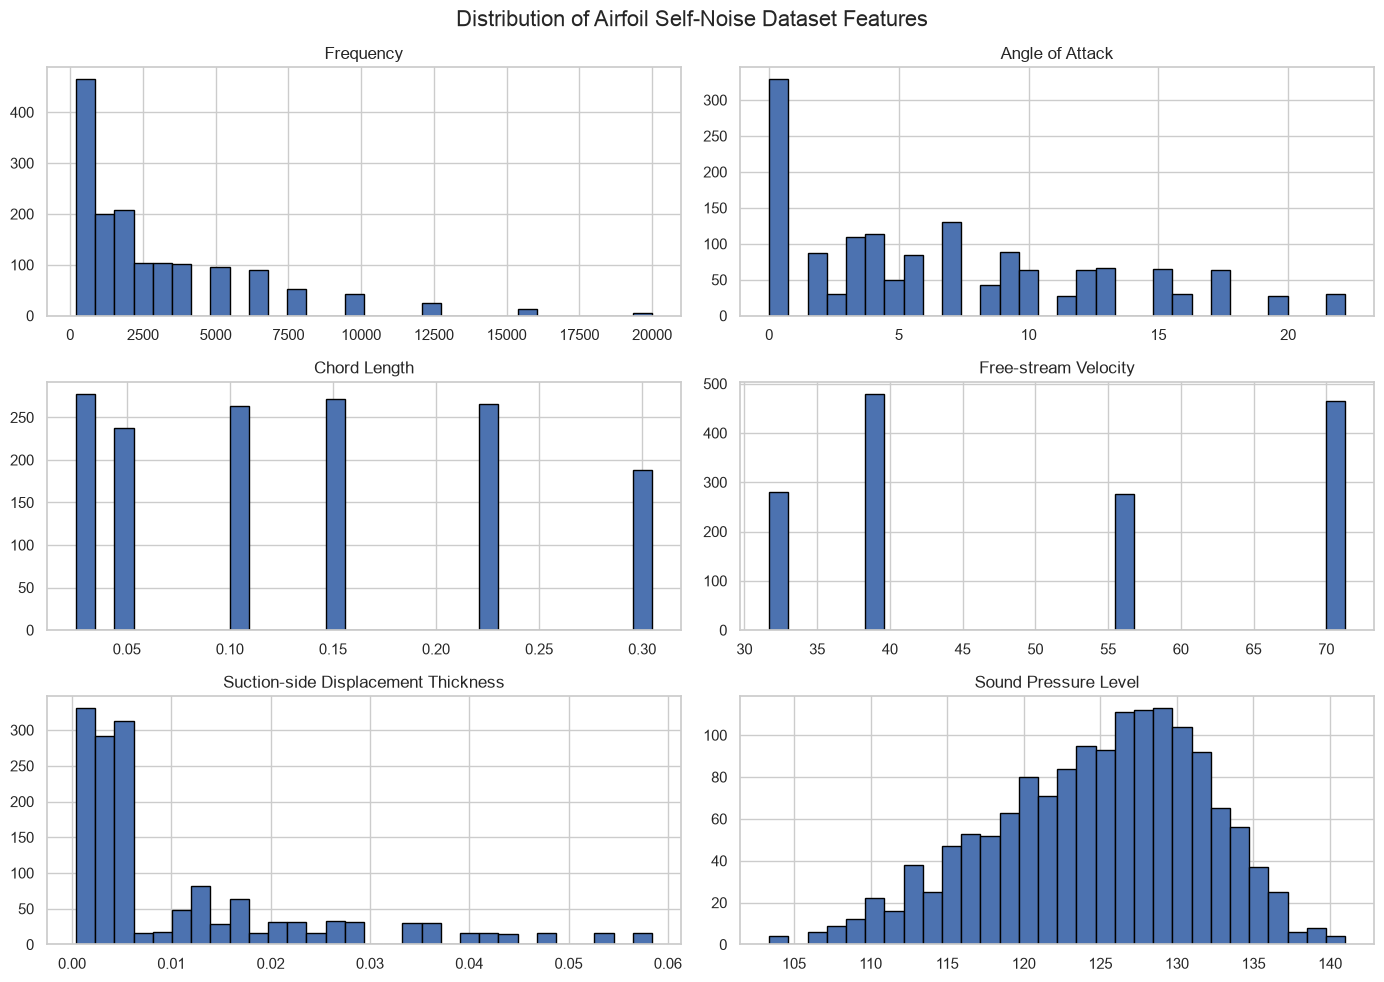

In [6]:
# Plot histograms for all dataset columns

df.hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Airfoil Self-Noise Dataset Features",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

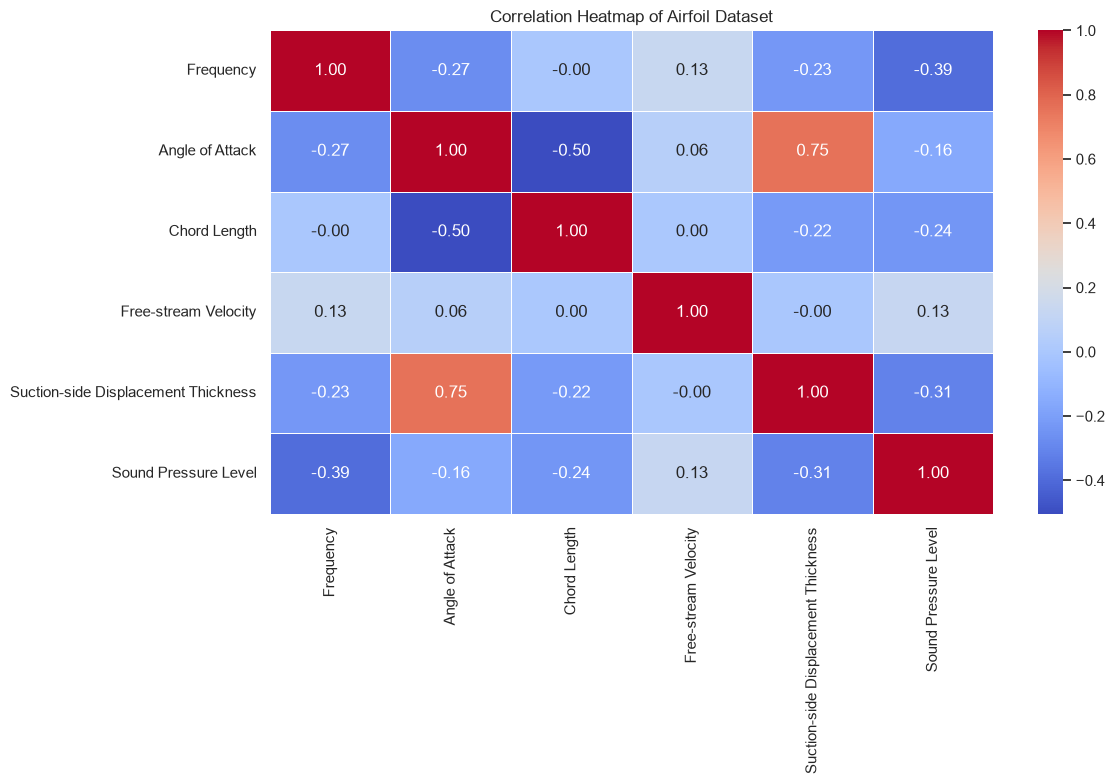

In [7]:
# Calculate correlation between all numerical features

correlation = df.corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Airfoil Dataset")
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

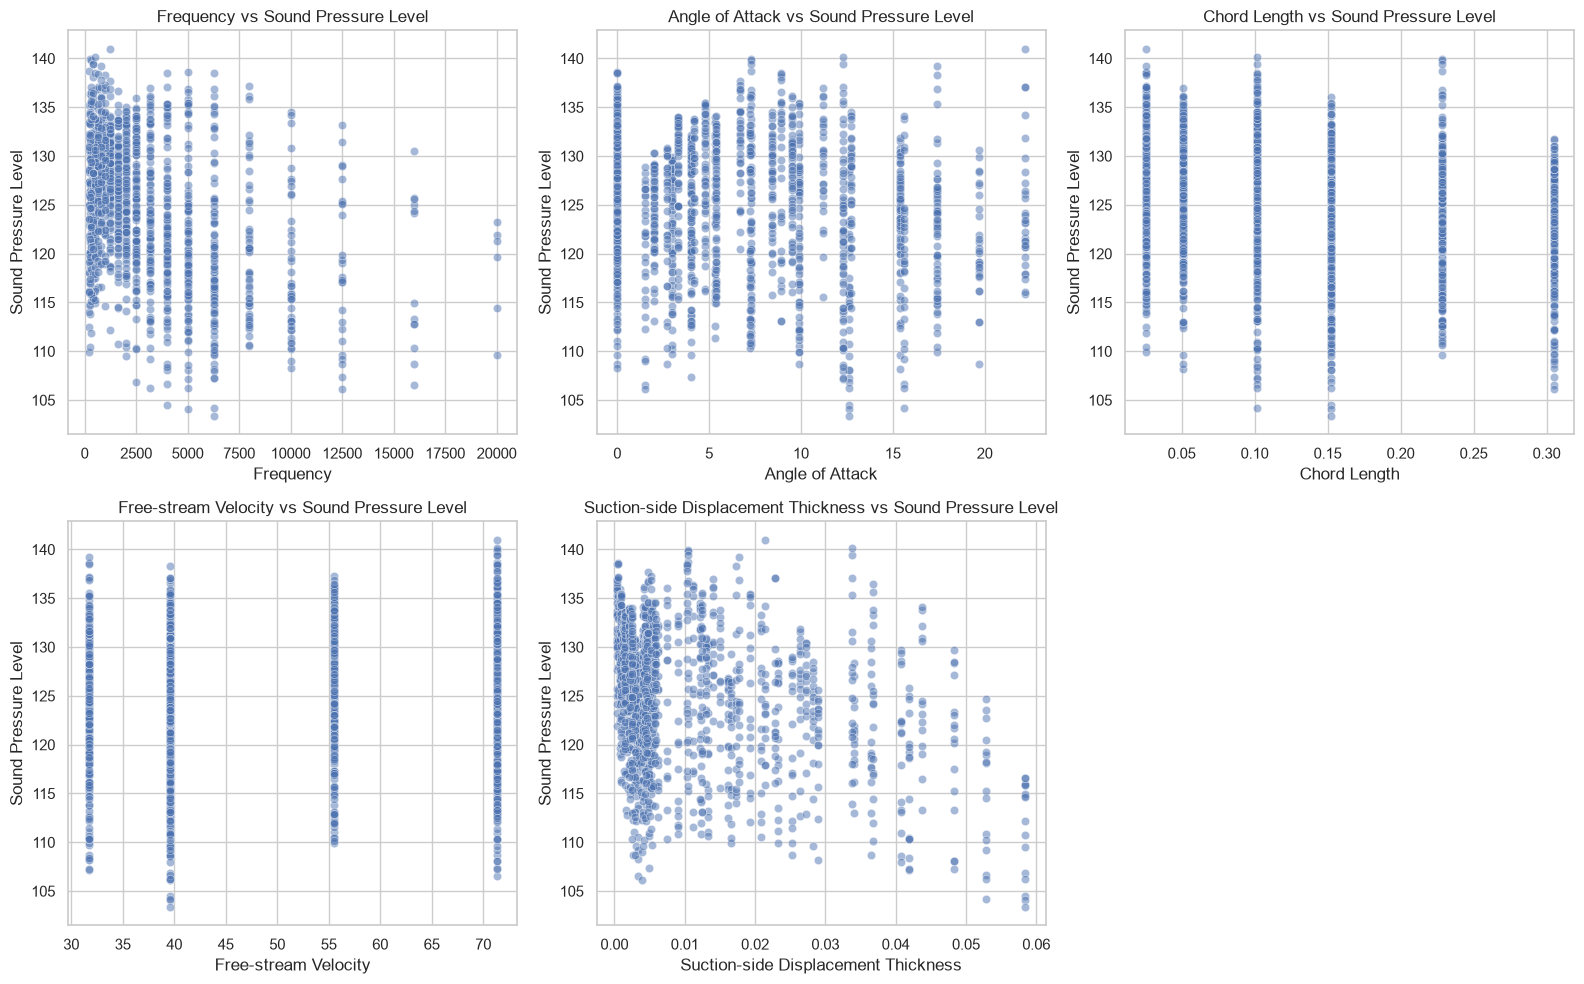

In [8]:
# Plot each input feature against Sound Pressure Level

features = [
    "Frequency",
    "Angle of Attack",
    "Chord Length",
    "Free-stream Velocity",
    "Suction-side Displacement Thickness"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, feature in enumerate(features):

    sns.scatterplot(
        data=df,
        x=feature,
        y="Sound Pressure Level",
        ax=axes[i],
        alpha=0.5
    )

    axes[i].set_title(f"{feature} vs Sound Pressure Level")

# Remove unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "feature_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Find correlation of every feature with the target variable

target_correlation = (
    df.corr()["Sound Pressure Level"]
    .drop("Sound Pressure Level")
    .sort_values(key=abs, ascending=False)
)

print("Correlation of input features with Sound Pressure Level:\n")
print(target_correlation)

print("\nDataset Summary:")
print("Total observations:", len(df))
print("Total features:", len(df.columns) - 1)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAverage Sound Pressure Level:")
print(round(df["Sound Pressure Level"].mean(), 2), "dB")

print("\nMinimum Sound Pressure Level:")
print(df["Sound Pressure Level"].min(), "dB")

print("\nMaximum Sound Pressure Level:")
print(df["Sound Pressure Level"].max(), "dB")

Correlation of input features with Sound Pressure Level:

Frequency                             -0.390711
Suction-side Displacement Thickness   -0.312670
Chord Length                          -0.236162
Angle of Attack                       -0.156108
Free-stream Velocity                   0.125103
Name: Sound Pressure Level, dtype: float64

Dataset Summary:
Total observations: 1503
Total features: 5
Missing values: 0
Duplicate rows: 0

Average Sound Pressure Level:
124.84 dB

Minimum Sound Pressure Level:
103.38 dB

Maximum Sound Pressure Level:
140.987 dB


## EDA Conclusions
1. The dataset contains 1503 observations and 5 input features.
2. The dataset was examined for missing values and duplicate records.
3. Histograms were generated to understand the distribution of individual features.
4. A correlation heatmap was used to examine relationships between numerical variables.
5. Scatter plots were generated to study the relationship between aerodynamic parameters and sound pressure level.
6. Correlation analysis was used to identify which input features have stronger linear relationships with the target variable.


### Key Findings
1. **Dataset:** The dataset has 1503 rows and 5 input features. There are no missing values or duplicate rows.
2. **Sound Levels:** The average sound pressure level is 124.84 dB. The lowest value is 103.38 dB, and the highest is 140.987 dB.
3. **Frequency:** Frequency has the strongest relationship with sound pressure level, with a correlation of -0.3907. This means higher frequencies generally tend to have lower sound levels in this dataset.
4. **Other Features:** Thickness, chord length, and angle of attack also show negative correlations with sound level. Free-stream velocity has a small positive correlation.
5. **Data Distribution:** The graphs show that frequency and thickness have more values towards the lower end, while sound pressure levels are mostly concentrated around the middle.
6. **Scatter Plots:** The scatter plots show that sound levels vary quite a lot, even for similar input values. So, predicting sound level using just one feature may not be enough.
7. **Overall Finding:** All five input features can be used to train our Linear Regression model and check how well it predicts airfoil noise.

Feature Importance Based on Correlation:
Frequency                             -0.390711
Suction-side Displacement Thickness   -0.312670
Chord Length                          -0.236162
Angle of Attack                       -0.156108
Free-stream Velocity                   0.125103
Name: Sound Pressure Level, dtype: float64


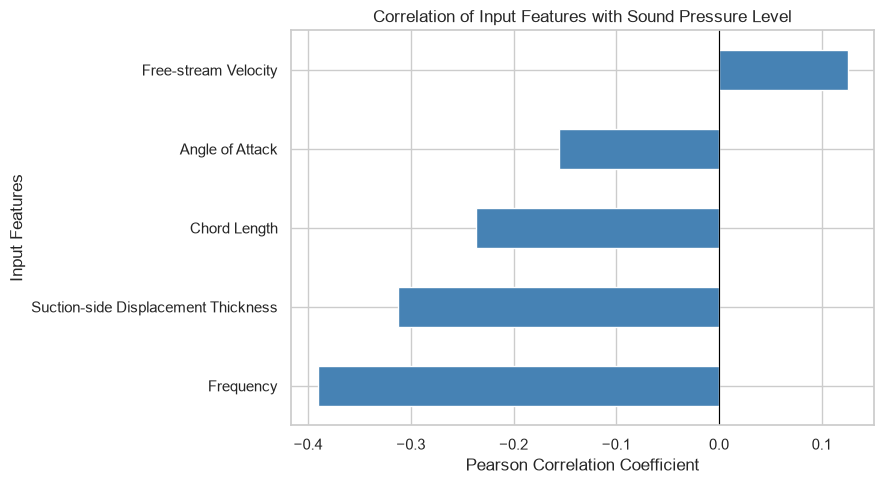

In [10]:
# Rank input features by their correlation with sound pressure level

target = "Sound Pressure Level"

feature_correlations = (
    df.corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

print("Feature Importance Based on Correlation:")
print(feature_correlations)

plt.figure(figsize=(9, 5))

feature_correlations.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Correlation of Input Features with Sound Pressure Level")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Input Features")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "feature_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()